In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from AI4AO.paths import DATA_DIR

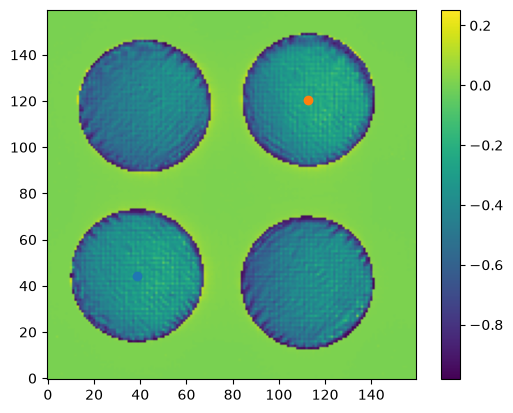

In [ ]:
imat = fits.getdata(DATA_DIR / "Chaos" / "20261102_145746_imat.fits") # TBT
m2c = fits.getdata(DATA_DIR / "Chaos" / "20261013_144305_m2c.fits")

imat_rms = np.std(imat,axis=1)

X,Y = np.meshgrid(np.arange(160),np.arange(160))

BL = (X<80)*(Y<80)
BR = (X>=80)*(Y<80)
TL = (X<80)*(Y>=80)
TR = (X>=80)*(Y>=80)

imat_rms_thr = imat_rms.reshape([160,160]) > 1e-3

cxbl = np.sum(X*imat_rms_thr*BL)/np.sum(imat_rms_thr*BL)
cybl = np.sum(Y*imat_rms_thr*BL)/np.sum(imat_rms_thr*BL)
cxbr = np.sum(X*imat_rms_thr*BR)/np.sum(imat_rms_thr*BR)
cybr = np.sum(Y*imat_rms_thr*BR)/np.sum(imat_rms_thr*BR)
cxtl = np.sum(X*imat_rms_thr*TL)/np.sum(imat_rms_thr*TL)
cytl = np.sum(Y*imat_rms_thr*TL)/np.sum(imat_rms_thr*TL)
cxtr = np.sum(X*imat_rms_thr*TR)/np.sum(imat_rms_thr*TR)
cytr = np.sum(Y*imat_rms_thr*TR)/np.sum(imat_rms_thr*TR)

radius = 29
rho = lambda cx,cy: np.sqrt((X-cx)**2+(Y-cy)**2)

cmask = rho(cxbl,cybl) <= radius
cmask = np.logical_or(rho(cxbr,cybr) <= radius,cmask)
cmask = np.logical_or(rho(cxtr,cytr) <= radius,cmask)
cmask = np.logical_or(rho(cxtl,cytl) <= radius,cmask)

plt.figure()
# plt.imshow(imat_rms_thr,origin='lower')
plt.imshow(imat_rms.reshape([160,160])/np.max(imat_rms)-cmask,origin='lower')
plt.plot(cxbl,cybl,'o')
plt.plot(cxtr,cytr,'o')
plt.colorbar()

validPixels = cmask.astype(bool)

np.save(DATA_DIR / "Chaos" / "20261013_144305_m2c.npy",m2c)
np.save(DATA_DIR / "Chaos" / "20261102_145746_imat.npy",imat[validPixels.flatten(),:])
np.save(DATA_DIR / "Chaos" / "20261102_145746_mask.npy",validPixels.astype(np.uint8))